In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [3]:
from src.conexao_banco import conn, cursor

- Primeira pergunta de negócio: Como a duração média das corridas se relaciona com o desempenho dos motoristas nas avaliações recebidas?

In [4]:
query = """
    SELECT "Avg_CTAT",
            "Driver_Ratings"
    FROM ncr_ride_bookings
    WHERE "Booking_Status" = 'Completed'
"""

In [5]:
duracao_media_avaliacoes = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_19496\1369848999.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  duracao_media_avaliacoes = pd.read_sql_query(query, conn)


In [6]:
correlacao_tempo_medio_avaliacao_corrida = duracao_media_avaliacoes.corr()

In [15]:
correlacao_tempo_medio_avaliacao_corrida.isna().sum()

Avg_CTAT          0
Driver_Ratings    0
dtype: int64

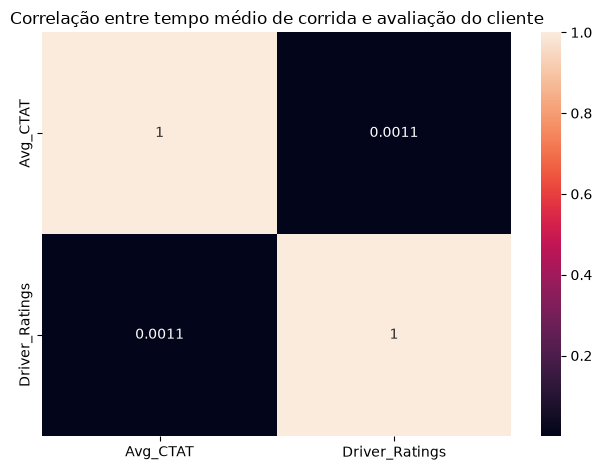

In [7]:
sns.heatmap(correlacao_tempo_medio_avaliacao_corrida, annot=True)
plt.title("Correlação entre tempo médio de corrida e avaliação do cliente")
plt.tight_layout()
plt.show()

In [8]:
correlacao_tempo_medio_avaliacao_corrida

,Avg_CTAT,Driver_Ratings
Avg_CTAT,1.000000,0.001129
Driver_Ratings,0.001129,1.000000


    Após a análise de correlação de Pearson entre a duração média das viagens e a avaliação dos clientes, foi obtido um coeficiente de 0,001129, indicando uma correlação positiva praticamente inexistente entre as variáveis. Dessa forma, os resultados não apontam para uma relação linear relevante entre a duração das viagens e as avaliações dos clientes.

- Segunda pergunta de negócio: Qual é a relação entre as avaliações dos clientes e as avaliações dos motoristas?

In [9]:
query = """
    SELECT "Driver_Ratings",
            "Customer_Rating"
    FROM ncr_ride_bookings
    WHERE "Booking_Status" = 'Completed'
"""

In [10]:
avaliacao_motorista_cliente = pd.read_sql_query(query, conn)

C:\Users\Victor\AppData\Local\Temp\ipykernel_19496\3816643564.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  avaliacao_motorista_cliente = pd.read_sql_query(query, conn)


In [11]:
correlacao_avaliacao_motorista_cliente = avaliacao_motorista_cliente.corr()

In [16]:
correlacao_avaliacao_motorista_cliente.isna().sum()

Driver_Ratings     0
Customer_Rating    0
dtype: int64

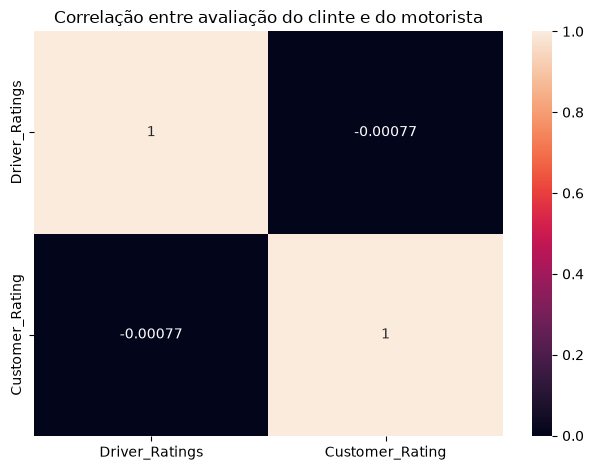

In [13]:
sns.heatmap(correlacao_avaliacao_motorista_cliente, annot=True)
plt.title("Correlação entre avaliação do clinte e do motorista")
plt.tight_layout()
plt.show()

In [14]:
correlacao_avaliacao_motorista_cliente

,Driver_Ratings,Customer_Rating
Driver_Ratings,1.000000,-0.000773
Customer_Rating,-0.000773,1.000000


    Após a análise de correlação de Pearson entre a avaliação dos motoristas e dos clientes na corrida, foi obtido um coeficiente de -0,00077, indicando uma correlação negativa praticamente inexistente entre as variáveis. Dessa forma, os resultados não apontam para uma relação linear relevante entre a avaliação dos motoristas e dos clientes na corrida.